In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

file_path = Path("../data/processed/model_eligible.csv")
model_eligible = pd.read_csv(file_path)

print("Dataset shape:", model_eligible.shape)
model_eligible.head()

Dataset shape: (2225, 30)


,CUSTOMER_ID,SIGNUP_DATE,AGE,GENDER,CITY,MEMBERSHIP_TIER,MARKETING_OPT_IN,PREFERRED_STORE_ID,PREFERRED_CATEGORY,HOME_STORE_PRICE_TIER,...,APP_SESSIONS_AVG_PRE,EMAILS_OPENED_AVG_PRE,SUPPORT_TICKETS_AVG_PRE,ACTIVE_MONTHS_PRE,RECENT_TRANSACTIONS,RECENT_SPEND,RECENT_APP_SESSIONS,RECENT_SUPPORT_TICKETS,CHURNED,INSUFFICIENT_HISTORY_FLAG
0,500001,2022-08-17,36.0,F,Madison,Silver,1,140,Frozen Foods,Value,...,2.142857,1.214286,0.214286,14.0,21.0,438.28,5.0,0.0,0,0
1,500002,2023-06-24,37.0,F,Spokane,Silver,0,119,Beverages,Mainstream,...,2.333333,0.333333,0.111111,9.0,12.0,357.11,5.0,0.0,0,0
2,500003,2021-03-31,53.0,Unknown,Tulsa,Gold,0,119,Frozen Foods,Mainstream,...,3.285714,0.428571,0.142857,14.0,14.0,489.49,6.0,2.0,0,0
3,500004,2021-07-08,52.0,F,Spokane,Gold,1,106,Snacks,Upscale,...,3.928571,1.428571,0.214286,14.0,16.0,367.99,10.0,0.0,0,0
4,500006,2022-09-14,44.0,F,Nashville,Silver,0,128,Snacks,Upscale,...,2.666667,0.466667,0.266667,14.0,4.0,116.51,6.0,2.0,0,0


In [4]:
churn_counts = model_eligible["CHURNED"].value_counts().sort_index()

print("0 = Stayed, 1 = Churned")
print(churn_counts)

print("\nChurn percentage:")
print((model_eligible["CHURNED"].value_counts(normalize=True) * 100).round(2))

0 = Stayed, 1 = Churned
CHURNED
0    1563
1     662
Name: count, dtype: int64

Churn percentage:
CHURNED
0    70.25
1    29.75
Name: proportion, dtype: float64


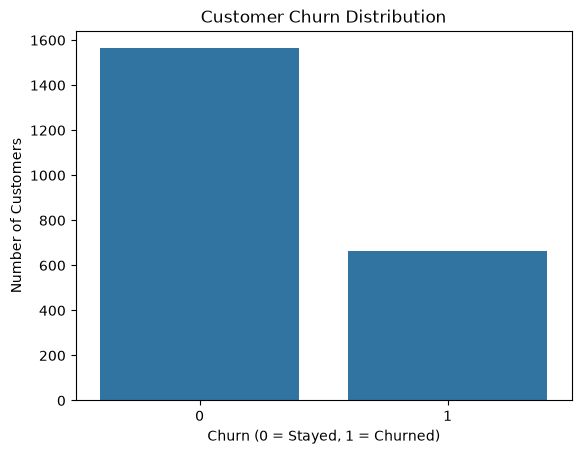

In [5]:
sns.countplot(data=model_eligible, x="CHURNED")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = Stayed, 1 = Churned)")
plt.ylabel("Number of Customers")
plt.show()

In [6]:
spending = model_eligible.groupby("CHURNED")[
    ["TOTAL_SPEND_PRE", "TRANSACTIONS_PRE"]
].mean()

print(spending)

         TOTAL_SPEND_PRE  TRANSACTIONS_PRE
CHURNED                                   
0            1655.991796         51.165707
1             749.212454         23.453172


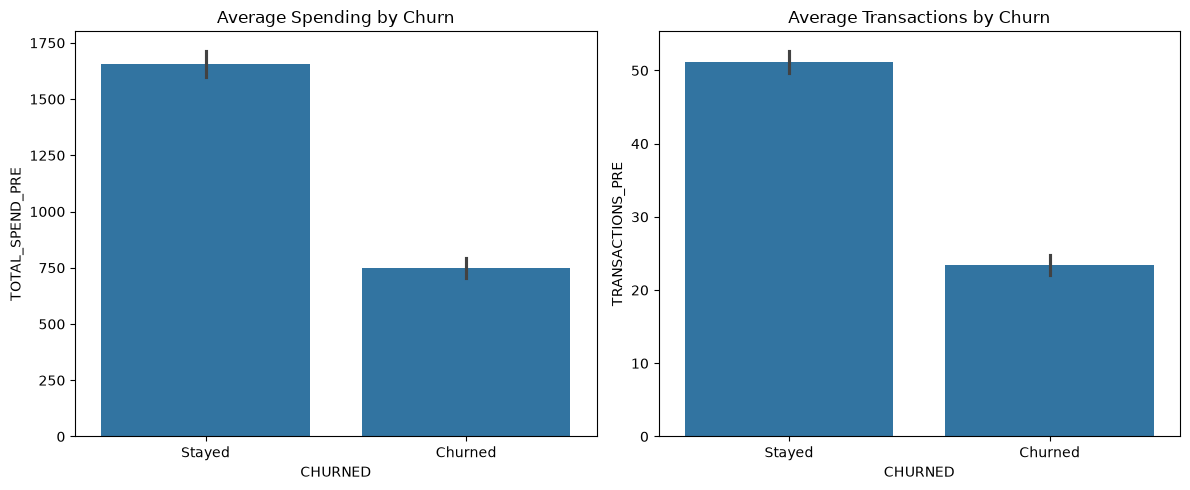

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=model_eligible, x="CHURNED",
            y="TOTAL_SPEND_PRE", ax=axes[0])
axes[0].set_title("Average Spending by Churn")
axes[0].set_xticks([0, 1], ["Stayed", "Churned"])

sns.barplot(data=model_eligible, x="CHURNED",
            y="TRANSACTIONS_PRE", ax=axes[1])
axes[1].set_title("Average Transactions by Churn")
axes[1].set_xticks([0, 1], ["Stayed", "Churned"])

plt.tight_layout()
plt.show()

In [8]:
tier_churn = pd.crosstab(
    model_eligible["MEMBERSHIP_TIER"],
    model_eligible["CHURNED"],
    normalize="index"
) * 100

tier_churn.columns = ["Stayed (%)", "Churned (%)"]
print(tier_churn.round(2))

                 Stayed (%)  Churned (%)
MEMBERSHIP_TIER                         
Gold                  72.02        27.98
Platinum              70.38        29.62
Silver                69.24        30.76


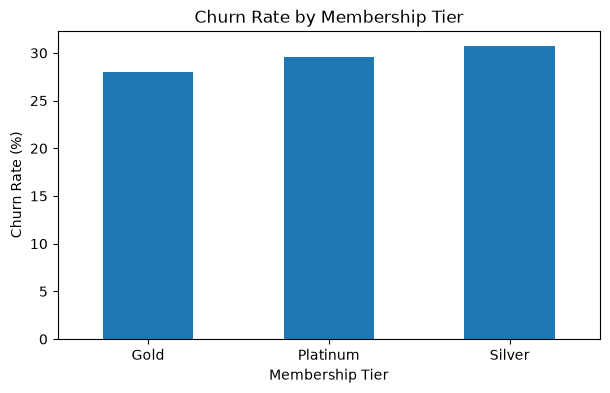

In [9]:
tier_churn["Churned (%)"].plot(kind="bar", figsize=(7, 4))

plt.title("Churn Rate by Membership Tier")
plt.xlabel("Membership Tier")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [10]:
engagement = model_eligible.groupby("CHURNED")[
    ["APP_SESSIONS_AVG_PRE", "EMAILS_OPENED_AVG_PRE"]
].mean()

print(engagement)

         APP_SESSIONS_AVG_PRE  EMAILS_OPENED_AVG_PRE
CHURNED                                             
0                    2.269658               1.106203
1                    1.215376               0.769055


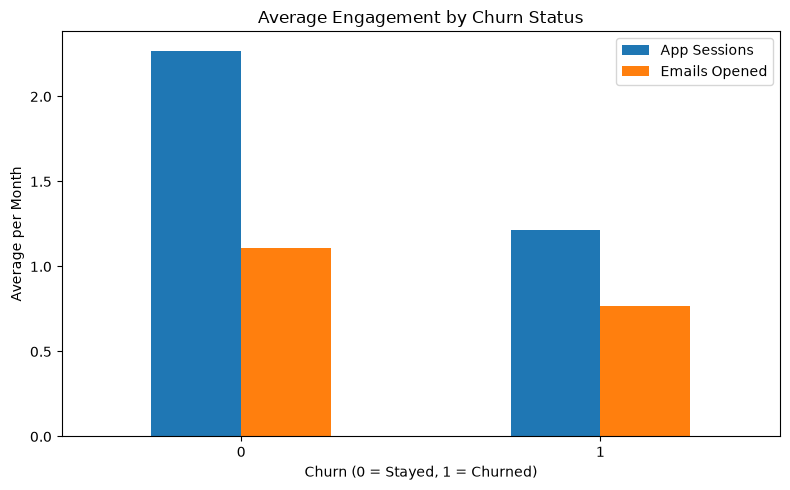

In [11]:
engagement.plot(kind="bar", figsize=(8, 5))

plt.title("Average Engagement by Churn Status")
plt.xlabel("Churn (0 = Stayed, 1 = Churned)")
plt.ylabel("Average per Month")
plt.xticks(rotation=0)
plt.legend(["App Sessions", "Emails Opened"])
plt.tight_layout()
plt.show()

In [12]:
print("Missing values in the eligible dataset:")
print(model_eligible.isna().sum()[model_eligible.isna().sum() > 0])

Missing values in the eligible dataset:
RECENT_TRANSACTIONS       449
RECENT_SPEND              449
RECENT_APP_SESSIONS       449
RECENT_SUPPORT_TICKETS    449
dtype: int64


In [3]:
recent_cols = [
    "RECENT_TRANSACTIONS",
    "RECENT_SPEND",
    "RECENT_APP_SESSIONS",
    "RECENT_SUPPORT_TICKETS"
]

print(model_eligible[recent_cols].isna().all(axis=1).value_counts())

False    1776
True      449
Name: count, dtype: int64


In [14]:
print("Missing recent transactions by churn status:")
print(
    model_eligible.groupby("CHURNED")["RECENT_TRANSACTIONS"]
    .apply(lambda x: x.isna().sum())
)

Missing recent transactions by churn status:
CHURNED
0      7
1    442
Name: RECENT_TRANSACTIONS, dtype: int64


In [11]:
file_path = Path("../data/raw/FreshBasket_Loyalty_Churn_Dataset.xlsx")

activity_model = pd.read_excel(
    file_path,
    sheet_name="fb Monthly Activity",
    header=1
).drop_duplicates()

activity_model["MONTH"] = pd.to_datetime(activity_model["MONTH"])

In [12]:
recent_activity_check = activity_model[
    (activity_model["MONTH"] >= "2024-01-01") &
    (activity_model["MONTH"] < "2024-04-01")
]

print("Customers with records in Jan–Mar 2024:",
      recent_activity_check["CUSTOMER_ID"].nunique())

print("Rows in Jan–Mar 2024:", len(recent_activity_check))

Customers with records in Jan–Mar 2024: 1800
Rows in Jan–Mar 2024: 4812


In [13]:
missing_recent = model_eligible.loc[
    model_eligible["RECENT_TRANSACTIONS"].isna(),
    "CUSTOMER_ID"
]

recent_ids = recent_activity_check["CUSTOMER_ID"].unique()

print("Missing-feature customers:", len(missing_recent))
print("Among them, with recent activity records:",
      missing_recent.isin(recent_ids).sum())
print("Among them, without recent activity records:",
      (~missing_recent.isin(recent_ids)).sum())

Missing-feature customers: 449
Among them, with recent activity records: 0
Among them, without recent activity records: 449


In [19]:
print(
    "Customers with no pre-April activity records:",
    (~model_eligible["CUSTOMER_ID"].isin(
        activity_model.loc[
            activity_model["MONTH"] < "2024-04-01",
            "CUSTOMER_ID"
        ].unique()
    )).sum()
)

Customers with no pre-April activity records: 0


In [5]:
features_to_compare = [
    "TOTAL_SPEND_PRE",
    "TRANSACTIONS_PRE",
    "APP_SESSIONS_AVG_PRE",
    "EMAILS_OPENED_AVG_PRE",
    "ACTIVE_MONTHS_PRE"
]

feature_summary = model_eligible.groupby("CHURNED")[features_to_compare].mean().T
feature_summary.columns = ["Stayed", "Churned"]

print(feature_summary.round(2))

                        Stayed  Churned
TOTAL_SPEND_PRE        1655.99   749.21
TRANSACTIONS_PRE         51.17    23.45
APP_SESSIONS_AVG_PRE      2.27     1.22
EMAILS_OPENED_AVG_PRE     1.11     0.77
ACTIVE_MONTHS_PRE        10.56     6.83


In [15]:
feature_summary.to_csv(
    "../data/processed/eda_feature_summary.csv"
)

print("EDA feature summary saved.")

EDA feature summary saved.


In [6]:
segment_columns = [
    "MEMBERSHIP_TIER",
    "GENDER",
    "HOME_STORE_PRICE_TIER",
    "PREFERRED_CATEGORY",
    "CITY",
]
segment_frames = []

for column in segment_columns:
    summary = model_eligible.groupby(column, dropna=False).agg(
        CUSTOMERS=("CHURNED", "size"),
        CHURNED_CUSTOMERS=("CHURNED", "sum"),
        CHURN_RATE=("CHURNED", "mean"),
    )
    summary.insert(0, "SEGMENT", column)
    summary.insert(1, "VALUE", summary.index.astype(str))
    segment_frames.append(summary.reset_index(drop=True))

segment_summary = pd.concat(segment_frames, ignore_index=True)
segment_summary["CHURN_RATE_PCT"] = segment_summary["CHURN_RATE"] * 100
segment_summary = segment_summary.drop(columns="CHURN_RATE")
segment_summary = segment_summary[segment_summary["CUSTOMERS"] >= 30]
segment_summary = segment_summary.sort_values(
    ["SEGMENT", "CHURN_RATE_PCT"], ascending=[True, False]
)

print("Segment churn rates (groups with at least 30 customers):")
display(segment_summary.round({"CHURN_RATE_PCT": 2}))
segment_summary.to_csv(
    Path("../data/processed/eda_segment_churn.csv"), index=False
)


Segment churn rates (groups with at least 30 customers):


,SEGMENT,VALUE,CUSTOMERS,CHURNED_CUSTOMERS,CHURN_RATE_PCT
19,CITY,Austin,222,80,36.04
21,CITY,Columbus,223,76,34.08
24,CITY,Nashville,207,63,30.43
26,CITY,Raleigh,254,77,30.31
20,CITY,Boise,209,62,29.67
22,CITY,Denver,226,65,28.76
28,CITY,Tulsa,253,72,28.46
23,CITY,Madison,219,61,27.85
25,CITY,Portland,205,54,26.34
27,CITY,Spokane,207,52,25.12


In [8]:
numeric_features = [
    "AGE",
    "TOTAL_SPEND_PRE",
    "TRANSACTIONS_PRE",
    "AVG_BASKET_VALUE_AVG_PRE",
    "PROMO_TXN_PCT_AVG_PRE",
    "APP_SESSIONS_AVG_PRE",
    "EMAILS_OPENED_AVG_PRE",
    "SUPPORT_TICKETS_AVG_PRE",
    "ACTIVE_MONTHS_PRE",
    "RECENT_TRANSACTIONS",
    "RECENT_SPEND",
    "RECENT_APP_SESSIONS",
    "RECENT_SUPPORT_TICKETS",
]

feature_comparison = model_eligible.groupby("CHURNED")[numeric_features].agg(
    ["mean", "median"]
).T
feature_comparison.columns = ["Stayed", "Churned"]
feature_comparison.index.names = ["FEATURE", "STATISTIC"]
feature_comparison = feature_comparison.reset_index()
print("Feature means and medians by churn status (missing values excluded per feature):")
display(feature_comparison.round(2))
feature_comparison.to_csv(
    Path("../data/processed/eda_numeric_comparison.csv"), index=False
)

recent_missing = model_eligible.groupby("CHURNED")[recent_cols].agg(
    lambda values: values.isna().mean() * 100
)
recent_missing.index = ["Stayed", "Churned"]
print("\nMissing recent-feature percentage by churn status:")
display(recent_missing.round(2))


Feature means and medians by churn status (missing values excluded per feature):


,FEATURE,STATISTIC,Stayed,Churned
0,AGE,mean,45.93,47.00
1,AGE,median,46.00,46.00
2,TOTAL_SPEND_PRE,mean,1655.99,749.21
3,TOTAL_SPEND_PRE,median,1538.46,589.48
4,TRANSACTIONS_PRE,mean,51.17,23.45
5,TRANSACTIONS_PRE,median,51.00,19.00
6,AVG_BASKET_VALUE_AVG_PRE,mean,30.90,25.41
7,AVG_BASKET_VALUE_AVG_PRE,median,30.71,25.59
8,PROMO_TXN_PCT_AVG_PRE,mean,0.28,0.24
9,PROMO_TXN_PCT_AVG_PRE,median,0.28,0.24



Missing recent-feature percentage by churn status:


,RECENT_TRANSACTIONS,RECENT_SPEND,RECENT_APP_SESSIONS,RECENT_SUPPORT_TICKETS
Stayed,0.45,0.45,0.45,0.45
Churned,66.77,66.77,66.77,66.77


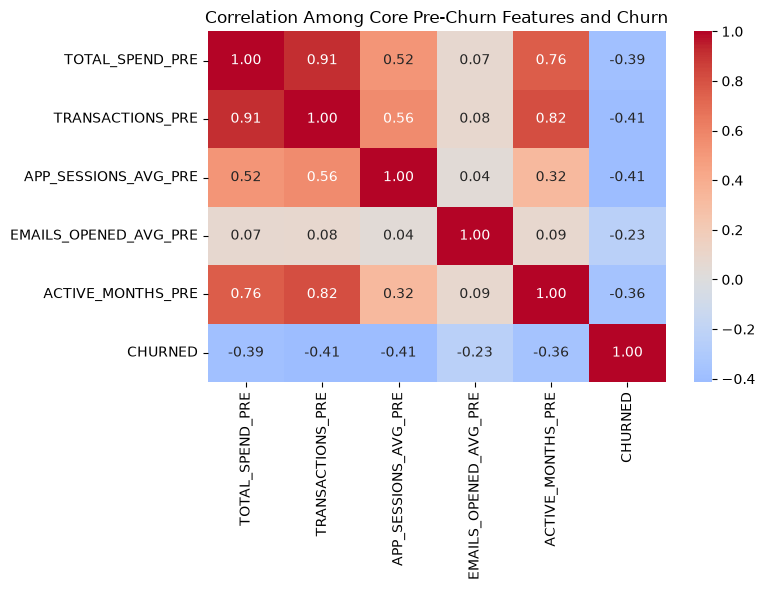

Relative mean difference (churned vs. stayed):


,Difference (%)
TOTAL_SPEND_PRE,-54.8
TRANSACTIONS_PRE,-54.2
APP_SESSIONS_AVG_PRE,-46.5
EMAILS_OPENED_AVG_PRE,-30.5
ACTIVE_MONTHS_PRE,-35.3



EDA takeaways: the eligible population contains 2,225 customers and 29.8% churn. In the pre-churn period, churned customers have lower average spending, transaction frequency, app engagement, email engagement, and active months in this dataset. Treat these as associations, not causal effects. Recent-period missing values remain missing in these comparisons and should be handled deliberately during modeling.


In [9]:
correlation_features = [
    "TOTAL_SPEND_PRE",
    "TRANSACTIONS_PRE",
    "APP_SESSIONS_AVG_PRE",
    "EMAILS_OPENED_AVG_PRE",
    "ACTIVE_MONTHS_PRE",
    "CHURNED",
]
correlations = model_eligible[correlation_features].corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Among Core Pre-Churn Features and Churn")
plt.tight_layout()
plt.show()

stayed_means = model_eligible.loc[model_eligible["CHURNED"] == 0, features_to_compare].mean()
churned_means = model_eligible.loc[model_eligible["CHURNED"] == 1, features_to_compare].mean()
relative_differences = (churned_means - stayed_means) / stayed_means.abs() * 100
print("Relative mean difference (churned vs. stayed):")
display(relative_differences.rename("Difference (%)").round(1).to_frame())

print(
    "\nEDA takeaways: the eligible population contains "
    f"{len(model_eligible):,} customers and "
    f"{model_eligible['CHURNED'].mean():.1%} churn. "
    "In the pre-churn period, churned customers have lower average "
    "spending, transaction frequency, app engagement, email engagement, "
    "and active months in this dataset. Treat these as associations, not "
    "causal effects. Recent-period missing values remain missing in these "
    "comparisons and should be handled deliberately during modeling."
)
